In [1]:
import sys

sys.path.insert(0, "../src")


import json
from datetime import datetime
from pathlib import Path

import modal
import torch
import torch.nn as nn
from core import Method, train
from IPython.display import Image, display
from model import CondEmbedderSigmaAndJump, ShortcutModel
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from unet import Unet

In [2]:
class ShortcutFlow(Method):
    def __init__(
        self,
        shortcut_frac: float,
        step_fracs: tuple[float, ...],
        img_shape: tuple[int, int, int],
    ):
        # Steps should be 1, ..., 1/32, the finest half step 1/64 is flow matching
        self.shortcut_frac, self.step_fracs = shortcut_frac, step_fracs
        self.img_shape = img_shape

    def loss(
        self, model: nn.Module, ema: nn.Module, imgs: torch.Tensor
    ) -> dict[str, torch.Tensor]:
        assert isinstance(model, ShortcutModel)

        batches = imgs.shape[0]
        device = imgs.device
        num_short = int(self.shortcut_frac * batches)
        noise = torch.randn_like(imgs)

        # Shortcut portion
        # Remember to keep t on the discretized grid
        jump_short = torch.tensor(self.step_fracs, device=device)[
            torch.randint(
                low=0, high=len(self.step_fracs), size=(num_short,), device=device
            )
        ]

        imgs_short = imgs[:num_short]
        t_short = (
            torch.rand(num_short, device=device) / jump_short
        ).floor() * jump_short

        x_short = (
            t_short[:, None, None, None] * imgs_short
            + (1 - t_short)[:, None, None, None] * noise[:num_short]
        )

        with torch.no_grad():
            v_1 = ema(x_short, t_short, jump_short / 2)
            x_mid = (x_short + v_1 * jump_short[:, None, None, None] / 2).clamp(-4, +4)

            t_mid = t_short + jump_short / 2
            v_2 = ema(x_mid, t_mid, jump_short / 2)

            # Follow the paper when we clamp
            target_short = ((v_1 + v_2) / 2).clamp(-4, +4)

        # Flow matching
        flow_grid_step = min(self.step_fracs) / 2

        t_flow = (
            torch.rand(batches - num_short, device=device) / flow_grid_step
        ).floor() * flow_grid_step

        x_flow = (
            t_flow[:, None, None, None] * imgs[num_short:]
            + (1 - t_flow)[:, None, None, None] * noise[num_short:]
        )
        target_flow = imgs[num_short:] - noise[num_short:]

        # Combining the two
        out = model(
            torch.cat([x_short, x_flow], dim=0),
            torch.cat([t_short, t_flow], dim=0),
            torch.cat([jump_short, torch.zeros(x_flow.shape[0], device=device)]),
        )
        target = torch.cat([target_short, target_flow])
        loss = ((out - target) ** 2).mean()

        return {"loss": loss, "report": loss.detach()}

    @torch.no_grad()
    def sample(self, model: nn.Module, num_samples: int, steps: int) -> torch.Tensor:
        assert 1 / steps in self.step_fracs

        device = next(model.parameters()).device
        jump = torch.full((num_samples,), 1 / steps, device=device)

        x = torch.randn((num_samples, *self.img_shape), device=device)

        for i in range(steps):
            t = torch.full((num_samples,), i / steps, device=device)
            v = model(x, t, jump)
            x = x + v / steps

        return x

In [3]:
transform = transforms.Compose(
    [
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),
    ]
)
dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
sigma_data: float = 0.5031378865242004

In [4]:
unet = Unet(
    inp_ch=3,
    inp_proj_ch=64,
    midcoder_ch=64,
    enc_dec_channels=(64, 64, 64, 64),
    out_ch=3,
    group_size=32,
    cond_dim=256,
    num_heads=8,
)
step_fracs = (1.0, 1 / 2, 1 / 4, 1 / 8, 1 / 16, 1 / 32)

# Note: t spans [0, 1] instead of the ~[-1.6, 1.1] of 0.25 * ln(sigma)
embedder = CondEmbedderSigmaAndJump(
    cond_dim=256, w_min_sigma=0.5, w_max_sigma=40.0, num_jumps=len(step_fracs)
)

flow_model = ShortcutModel(unet, embedder)


shortcut_method = ShortcutFlow(
    shortcut_frac=0.25,
    step_fracs=step_fracs,
    img_shape=(3, 32, 32),
)

In [5]:
app = modal.App("shortcut-vanilla")

image = (
    modal.Image.debian_slim(python_version="3.13")
    .uv_sync(uv_project_dir="../../..", extra_options="--no-dev")
    .add_local_python_source("model", "emb", "unet", "core")
)
data_volume = modal.Volume.from_name("exp-diffusion-cfar", create_if_missing=True)

In [6]:
@app.function(
    image=image,
    gpu="H100",
    timeout=4 * 60 * 60,
    volumes={"/data": data_volume},
    serialized=True,
)
def run(model: nn.Module, method: Method, run_name: str):
    loader = DataLoader(
        datasets.CIFAR10(root="/data", train=True, download=True, transform=transform),
        batch_size=512,
        shuffle=True,
        num_workers=4,
        persistent_workers=True,
    )
    run_dir = Path("/data/runs") / run_name
    run_dir.mkdir(parents=True, exist_ok=True)

    for row, png in train(
        model,
        method,
        loader,
        epochs=500,
        eval_every=50,
        lr=1e-3,
        min_lr=1e-5,
        warmup_steps=1000,
        weight_decay=1e-2,
        ema_decay=0.999,
        fid_batches=2,
        fid_batch_size=5120,
        fid_chunk_size=512,
    ):
        # Note: Modal commits the volume in the background every few seconds, so the
        # metrics survive the client disconnecting
        with open(run_dir / "metrics.jsonl", "a") as f:
            f.write(json.dumps(row) + "\n")
        yield row, png

epoch 0 | loss 0.8513 | train 9s
epoch 1 | loss 0.4334 | train 8s
epoch 2 | loss 0.2389 | train 8s
epoch 3 | loss 0.1986 | train 8s
epoch 4 | loss 0.1831 | train 8s
epoch 5 | loss 0.1712 | train 8s
epoch 6 | loss 0.1652 | train 8s
epoch 7 | loss 0.1608 | train 8s
epoch 8 | loss 0.1574 | train 8s
epoch 9 | loss 0.1557 | train 8s
epoch 10 | loss 0.1522 | train 8s
epoch 11 | loss 0.1494 | train 8s
epoch 12 | loss 0.1494 | train 8s
epoch 13 | loss 0.1469 | train 8s
epoch 14 | loss 0.1465 | train 8s
epoch 15 | loss 0.1447 | train 8s
epoch 16 | loss 0.1440 | train 8s
epoch 17 | loss 0.1435 | train 8s
epoch 18 | loss 0.1425 | train 8s
epoch 19 | loss 0.1430 | train 8s
epoch 20 | loss 0.1435 | train 8s
epoch 21 | loss 0.1425 | train 8s
epoch 22 | loss 0.1413 | train 8s
epoch 23 | loss 0.1420 | train 8s
epoch 24 | loss 0.1410 | train 8s
epoch 25 | loss 0.1393 | train 8s
epoch 26 | loss 0.1398 | train 8s
epoch 27 | loss 0.1408 | train 8s
epoch 28 | loss 0.1400 | train 8s
epoch 29 | loss 0.1386 |

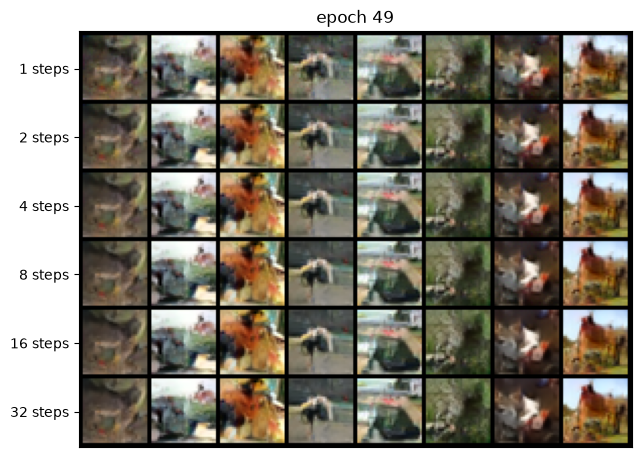

epoch 50 | loss 0.1362 | train 8s
epoch 51 | loss 0.1365 | train 8s
epoch 52 | loss 0.1366 | train 8s
epoch 53 | loss 0.1366 | train 8s
epoch 54 | loss 0.1361 | train 8s
epoch 55 | loss 0.1359 | train 8s
epoch 56 | loss 0.1361 | train 8s
epoch 57 | loss 0.1360 | train 8s
epoch 58 | loss 0.1353 | train 8s
epoch 59 | loss 0.1354 | train 8s
epoch 60 | loss 0.1357 | train 8s
epoch 61 | loss 0.1348 | train 8s
epoch 62 | loss 0.1351 | train 8s
epoch 63 | loss 0.1349 | train 8s
epoch 64 | loss 0.1353 | train 8s
epoch 65 | loss 0.1352 | train 8s
epoch 66 | loss 0.1350 | train 8s
epoch 67 | loss 0.1344 | train 8s
epoch 68 | loss 0.1355 | train 8s
epoch 69 | loss 0.1347 | train 8s
epoch 70 | loss 0.1352 | train 8s
epoch 71 | loss 0.1352 | train 8s
epoch 72 | loss 0.1348 | train 8s
epoch 73 | loss 0.1344 | train 9s
epoch 74 | loss 0.1353 | train 8s
epoch 75 | loss 0.1346 | train 8s
epoch 76 | loss 0.1354 | train 8s
epoch 77 | loss 0.1337 | train 8s
epoch 78 | loss 0.1349 | train 8s
epoch 79 | los

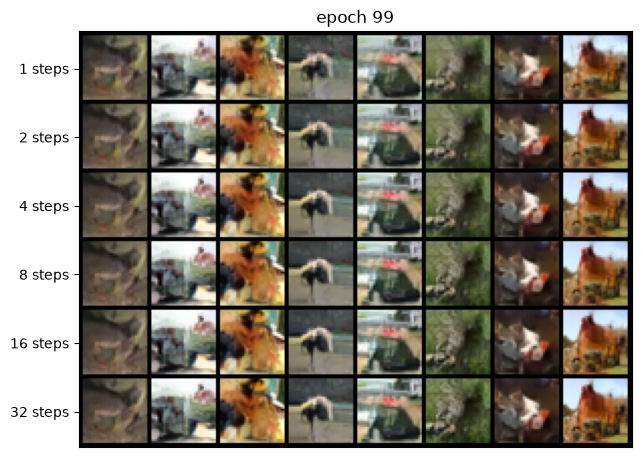

epoch 100 | loss 0.1335 | train 8s
epoch 101 | loss 0.1335 | train 8s
epoch 102 | loss 0.1331 | train 8s
epoch 103 | loss 0.1332 | train 8s
epoch 104 | loss 0.1338 | train 8s
epoch 105 | loss 0.1333 | train 8s
epoch 106 | loss 0.1334 | train 8s
epoch 107 | loss 0.1330 | train 8s
epoch 108 | loss 0.1332 | train 8s
epoch 109 | loss 0.1331 | train 8s
epoch 110 | loss 0.1332 | train 8s
epoch 111 | loss 0.1333 | train 8s
epoch 112 | loss 0.1332 | train 8s
epoch 113 | loss 0.1327 | train 8s
epoch 114 | loss 0.1327 | train 8s
epoch 115 | loss 0.1322 | train 8s
epoch 116 | loss 0.1335 | train 8s
epoch 117 | loss 0.1329 | train 8s
epoch 118 | loss 0.1329 | train 8s
epoch 119 | loss 0.1321 | train 8s
epoch 120 | loss 0.1329 | train 8s
epoch 121 | loss 0.1330 | train 8s
epoch 122 | loss 0.1325 | train 9s
epoch 123 | loss 0.1327 | train 8s
epoch 124 | loss 0.1324 | train 8s
epoch 125 | loss 0.1329 | train 8s
epoch 126 | loss 0.1323 | train 8s
epoch 127 | loss 0.1326 | train 8s
epoch 128 | loss 0.1

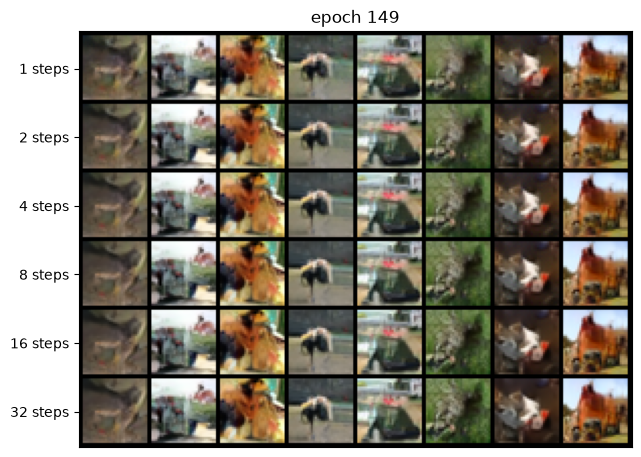

epoch 150 | loss 0.1318 | train 7s
epoch 151 | loss 0.1316 | train 7s
epoch 152 | loss 0.1323 | train 8s
epoch 153 | loss 0.1323 | train 7s
epoch 154 | loss 0.1315 | train 8s
epoch 155 | loss 0.1319 | train 8s
epoch 156 | loss 0.1328 | train 8s
epoch 157 | loss 0.1320 | train 9s
epoch 158 | loss 0.1320 | train 8s
epoch 159 | loss 0.1316 | train 8s
epoch 160 | loss 0.1313 | train 8s
epoch 161 | loss 0.1318 | train 8s
epoch 162 | loss 0.1312 | train 8s
epoch 163 | loss 0.1319 | train 8s
epoch 164 | loss 0.1315 | train 8s
epoch 165 | loss 0.1308 | train 8s
epoch 166 | loss 0.1313 | train 8s
epoch 167 | loss 0.1314 | train 8s
epoch 168 | loss 0.1316 | train 8s
epoch 169 | loss 0.1316 | train 8s
epoch 170 | loss 0.1314 | train 8s
epoch 171 | loss 0.1315 | train 8s
epoch 172 | loss 0.1311 | train 8s
epoch 173 | loss 0.1312 | train 8s
epoch 174 | loss 0.1320 | train 8s
epoch 175 | loss 0.1308 | train 8s
epoch 176 | loss 0.1314 | train 8s
epoch 177 | loss 0.1313 | train 8s
epoch 178 | loss 0.1

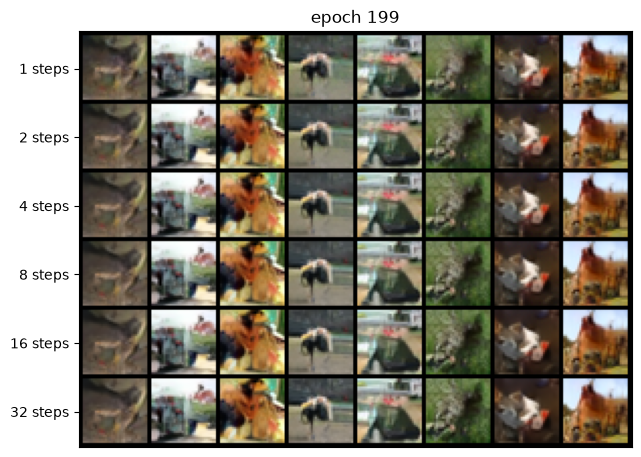

epoch 200 | loss 0.1308 | train 8s
epoch 201 | loss 0.1308 | train 8s
epoch 202 | loss 0.1309 | train 8s
epoch 203 | loss 0.1309 | train 8s
epoch 204 | loss 0.1311 | train 8s
epoch 205 | loss 0.1309 | train 8s
epoch 206 | loss 0.1312 | train 8s
epoch 207 | loss 0.1306 | train 8s
epoch 208 | loss 0.1306 | train 9s
epoch 209 | loss 0.1307 | train 8s
epoch 210 | loss 0.1309 | train 8s
epoch 211 | loss 0.1304 | train 8s
epoch 212 | loss 0.1314 | train 8s
epoch 213 | loss 0.1306 | train 8s
epoch 214 | loss 0.1306 | train 8s
epoch 215 | loss 0.1309 | train 8s
epoch 216 | loss 0.1303 | train 8s
epoch 217 | loss 0.1312 | train 8s
epoch 218 | loss 0.1308 | train 8s
epoch 219 | loss 0.1304 | train 8s
epoch 220 | loss 0.1305 | train 9s
epoch 221 | loss 0.1304 | train 8s
epoch 222 | loss 0.1309 | train 8s
epoch 223 | loss 0.1306 | train 8s
epoch 224 | loss 0.1304 | train 8s
epoch 225 | loss 0.1308 | train 8s
epoch 226 | loss 0.1304 | train 8s
epoch 227 | loss 0.1310 | train 8s
epoch 228 | loss 0.1

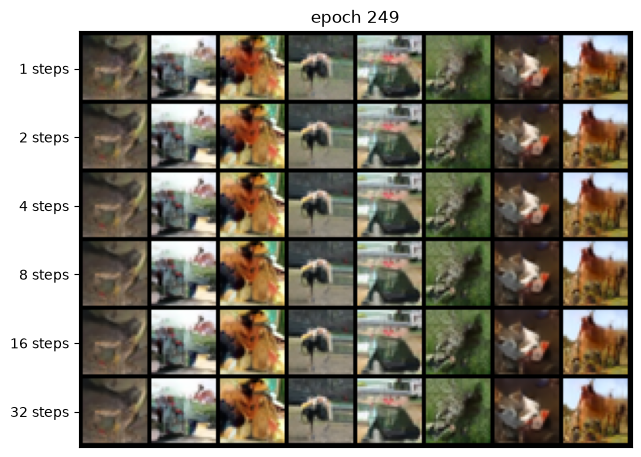

epoch 250 | loss 0.1302 | train 10s
epoch 251 | loss 0.1301 | train 8s
epoch 252 | loss 0.1304 | train 8s
epoch 253 | loss 0.1300 | train 8s
epoch 254 | loss 0.1304 | train 8s
epoch 255 | loss 0.1301 | train 8s
epoch 256 | loss 0.1301 | train 8s
epoch 257 | loss 0.1302 | train 8s
epoch 258 | loss 0.1299 | train 8s
epoch 259 | loss 0.1301 | train 8s
epoch 260 | loss 0.1300 | train 8s
epoch 261 | loss 0.1300 | train 8s
epoch 262 | loss 0.1299 | train 8s
epoch 263 | loss 0.1301 | train 8s
epoch 264 | loss 0.1300 | train 8s
epoch 265 | loss 0.1298 | train 8s
epoch 266 | loss 0.1299 | train 8s
epoch 267 | loss 0.1301 | train 8s
epoch 268 | loss 0.1297 | train 8s
epoch 269 | loss 0.1299 | train 8s
epoch 270 | loss 0.1299 | train 8s
epoch 271 | loss 0.1298 | train 8s
epoch 272 | loss 0.1297 | train 8s
epoch 273 | loss 0.1295 | train 8s
epoch 274 | loss 0.1304 | train 8s
epoch 275 | loss 0.1303 | train 8s
epoch 276 | loss 0.1298 | train 8s
epoch 277 | loss 0.1301 | train 8s
epoch 278 | loss 0.

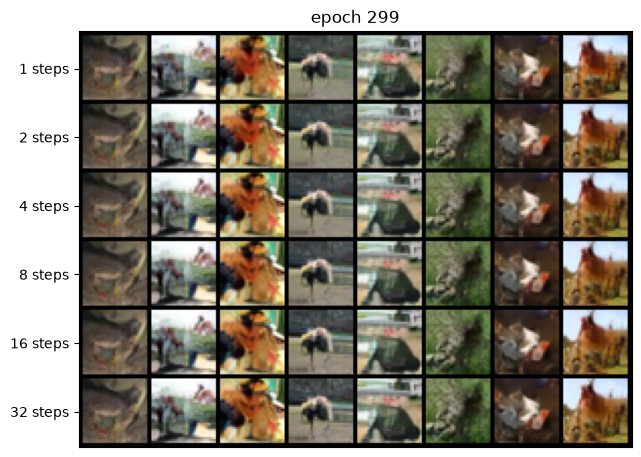

epoch 300 | loss 0.1295 | train 8s
epoch 301 | loss 0.1298 | train 8s
epoch 302 | loss 0.1290 | train 8s
epoch 303 | loss 0.1292 | train 9s
epoch 304 | loss 0.1298 | train 8s
epoch 305 | loss 0.1300 | train 8s
epoch 306 | loss 0.1295 | train 8s
epoch 307 | loss 0.1294 | train 8s
epoch 308 | loss 0.1296 | train 8s
epoch 309 | loss 0.1295 | train 8s
epoch 310 | loss 0.1291 | train 8s
epoch 311 | loss 0.1296 | train 8s
epoch 312 | loss 0.1295 | train 8s
epoch 313 | loss 0.1294 | train 8s
epoch 314 | loss 0.1297 | train 8s
epoch 315 | loss 0.1291 | train 8s
epoch 316 | loss 0.1295 | train 8s
epoch 317 | loss 0.1299 | train 8s
epoch 318 | loss 0.1294 | train 7s
epoch 319 | loss 0.1292 | train 8s
epoch 320 | loss 0.1297 | train 8s
epoch 321 | loss 0.1289 | train 8s
epoch 322 | loss 0.1293 | train 7s
epoch 323 | loss 0.1295 | train 8s
epoch 324 | loss 0.1290 | train 8s
epoch 325 | loss 0.1289 | train 8s
epoch 326 | loss 0.1295 | train 7s
epoch 327 | loss 0.1293 | train 9s
epoch 328 | loss 0.1

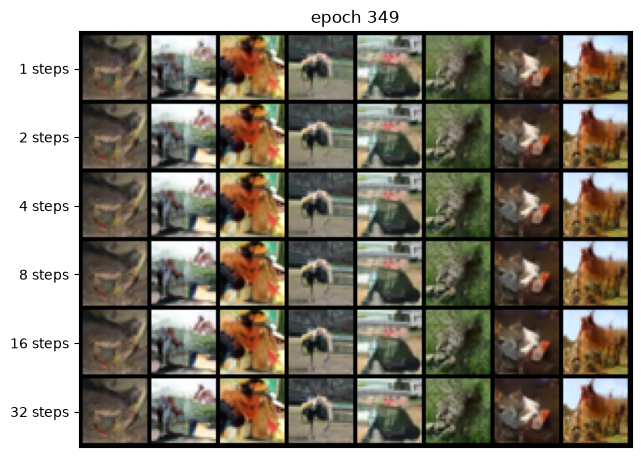

epoch 350 | loss 0.1294 | train 8s
epoch 351 | loss 0.1292 | train 8s
epoch 352 | loss 0.1290 | train 8s
epoch 353 | loss 0.1290 | train 8s
epoch 354 | loss 0.1288 | train 8s
epoch 355 | loss 0.1288 | train 8s
epoch 356 | loss 0.1289 | train 8s
epoch 357 | loss 0.1286 | train 8s
epoch 358 | loss 0.1293 | train 8s
epoch 359 | loss 0.1289 | train 8s
epoch 360 | loss 0.1290 | train 8s
epoch 361 | loss 0.1288 | train 8s
epoch 362 | loss 0.1294 | train 8s
epoch 363 | loss 0.1283 | train 8s
epoch 364 | loss 0.1283 | train 8s
epoch 365 | loss 0.1287 | train 8s
epoch 366 | loss 0.1292 | train 8s
epoch 367 | loss 0.1290 | train 8s
epoch 368 | loss 0.1291 | train 8s
epoch 369 | loss 0.1282 | train 8s
epoch 370 | loss 0.1286 | train 8s
epoch 371 | loss 0.1286 | train 8s
epoch 372 | loss 0.1292 | train 8s
epoch 373 | loss 0.1288 | train 8s
epoch 374 | loss 0.1284 | train 8s
epoch 375 | loss 0.1283 | train 9s
epoch 376 | loss 0.1291 | train 8s
epoch 377 | loss 0.1283 | train 8s
epoch 378 | loss 0.1

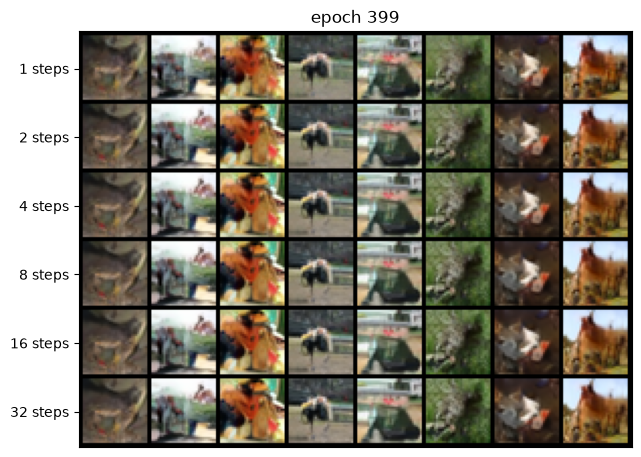

epoch 400 | loss 0.1282 | train 8s
epoch 401 | loss 0.1285 | train 8s
epoch 402 | loss 0.1285 | train 8s
epoch 403 | loss 0.1290 | train 8s
epoch 404 | loss 0.1286 | train 8s
epoch 405 | loss 0.1283 | train 8s
epoch 406 | loss 0.1288 | train 8s
epoch 407 | loss 0.1284 | train 8s
epoch 408 | loss 0.1296 | train 8s
epoch 409 | loss 0.1280 | train 8s
epoch 410 | loss 0.1280 | train 8s
epoch 411 | loss 0.1284 | train 8s
epoch 412 | loss 0.1288 | train 8s
epoch 413 | loss 0.1283 | train 8s
epoch 414 | loss 0.1283 | train 8s
epoch 415 | loss 0.1283 | train 8s
epoch 416 | loss 0.1287 | train 8s
epoch 417 | loss 0.1282 | train 8s
epoch 418 | loss 0.1286 | train 7s
epoch 419 | loss 0.1279 | train 8s
epoch 420 | loss 0.1288 | train 8s
epoch 421 | loss 0.1291 | train 8s
epoch 422 | loss 0.1284 | train 8s
epoch 423 | loss 0.1286 | train 8s
epoch 424 | loss 0.1285 | train 8s
epoch 425 | loss 0.1284 | train 8s
epoch 426 | loss 0.1283 | train 8s
epoch 427 | loss 0.1286 | train 8s
epoch 428 | loss 0.1

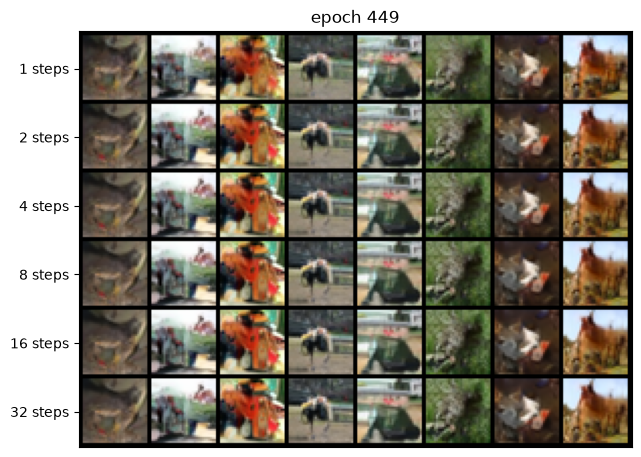

epoch 450 | loss 0.1281 | train 8s
epoch 451 | loss 0.1284 | train 8s
epoch 452 | loss 0.1291 | train 8s
epoch 453 | loss 0.1281 | train 8s
epoch 454 | loss 0.1288 | train 8s
epoch 455 | loss 0.1285 | train 8s
epoch 456 | loss 0.1276 | train 8s
epoch 457 | loss 0.1286 | train 8s
epoch 458 | loss 0.1281 | train 8s
epoch 459 | loss 0.1282 | train 8s
epoch 460 | loss 0.1277 | train 8s
epoch 461 | loss 0.1282 | train 7s
epoch 462 | loss 0.1286 | train 8s
epoch 463 | loss 0.1286 | train 8s
epoch 464 | loss 0.1281 | train 8s
epoch 465 | loss 0.1283 | train 8s
epoch 466 | loss 0.1274 | train 7s
epoch 467 | loss 0.1288 | train 8s
epoch 468 | loss 0.1277 | train 8s
epoch 469 | loss 0.1284 | train 8s
epoch 470 | loss 0.1277 | train 9s
epoch 471 | loss 0.1279 | train 8s
epoch 472 | loss 0.1278 | train 8s
epoch 473 | loss 0.1283 | train 8s
epoch 474 | loss 0.1280 | train 8s
epoch 475 | loss 0.1279 | train 8s
epoch 476 | loss 0.1284 | train 8s
epoch 477 | loss 0.1278 | train 8s
epoch 478 | loss 0.1

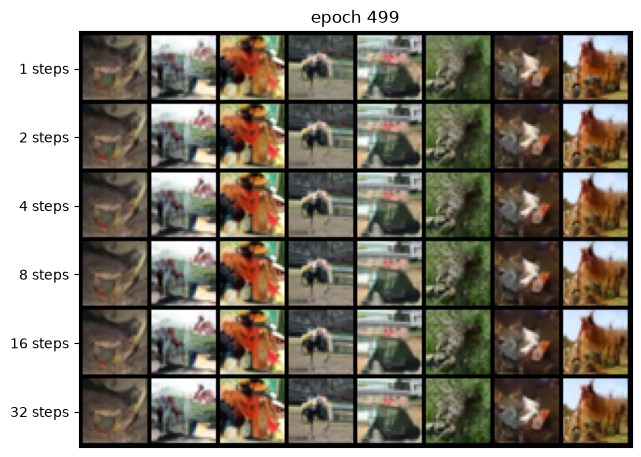

: 

In [ ]:
results_dir = Path("results") / f"shortcut-vanilla-{datetime.now():%Y%m%d-%H%M%S}"
(results_dir / "samples").mkdir(parents=True)

# Note: detached so the run keeps going if the client disconnects, stop it with
# modal app stop <app id>
with app.run(detach=True):
    for row, png in run.remote_gen(flow_model, shortcut_method, results_dir.name):
        with open(results_dir / "metrics.jsonl", "a") as f:
            f.write(json.dumps(row) + "\n")
        print(
            f"epoch {row['epoch']} | loss {row['loss']:.4f}"
            f" | train {row['train_sec']:.0f}s"
        )

        # FID and samples only come with eval epochs
        if png is not None:
            fid_str = "  ".join(
                f"{steps}: {value:.1f}" for steps, value in row["fid"].items()
            )
            print(f"  FID {fid_str} | {row['fid_sec']:.0f}s")
            (results_dir / "samples" / f"epoch_{row['epoch']:03d}.png").write_bytes(png)
            display(Image(data=png))